# Sentience Governor + LangChain: a beginner's notebook

**Sentience Governor** is a governance and observability layer for AI agents.
It watches what an agent does — which tools it calls, when it starts and stops, what
state it's in — and emits structured events you can inspect, log, or send to a dashboard.
Think of it as a flight-data recorder for an AI agent: it does not change the agent's
behavior, it just observes it.

This notebook shows the **callback integration pattern**, which is the exact mechanism
LangChain provides for hooking observation into an agent. LangChain agents already
fire lifecycle events (chain start/end, LLM start/end, tool start/end) regardless of
what the agent is actually doing. A *callback handler* is a small object that receives
those events. Sentience Governor ships a handler that turns those events into
governance events — and because we attach the handler through LangChain's standard
config, **no part of the agent itself has to change** to become observable.


## Install dependencies

We install LangChain, the Groq integration, LangChain Community (for the web search tool),
Sentience Governor itself, and pandas for the summary table at the end.


## API key

We need a Groq API key to run the language model. Groq offers a free tier — you can
sign up and grab a key at https://console.groq.com.

We'll enter the key below using `getpass`, which reads from the keyboard without
echoing it back. The key is stored only in the running notebook's environment; it is
never printed, never written into this notebook file, and never persisted to disk.


In [1]:
import os
from getpass import getpass

os.environ["GROQ_API_KEY"] = getpass("Enter your GROQ_API_KEY: ")

## Define the tool

LangChain agents act by calling **tools**, which are just regular Python functions
decorated with `@tool`. The agent decides, based on the user's request, when (and
how many times) to call a tool.

To keep this example self-contained, we define one trivial, deterministic tool — a
fake weather lookup that returns a hard-coded string. There is no real API call and
no network dependency beyond the LLM call itself.


In [2]:
from langchain_core.tools import tool

@tool
def get_weather(city: str) -> str:
    """Look up the current weather in a given city"""
    return f"The weather in {city} is 25 degrees celsius and cloudy"

## Add a second tool: live web search

So far our agent has one tool, a mocked weather lookup. Let's give it a second, *real* tool:
a live web search. We use `DuckDuckGoSearchRun` from `langchain-community`, which is handy
for a notebook like this because it needs no API key and no signup — unlike Google or Bing
search tools, which would each require you to provision a credential. That keeps the notebook
runnable for anyone who has a Groq key.


In [3]:
from langchain_community.tools import DuckDuckGoSearchRun

search_web = DuckDuckGoSearchRun()

/var/folders/d_/rqsk7t093dlg0nzx8rc5n4fh0000gn/T/ipykernel_52708/3112817857.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


## Define the agent

We build a tool-calling agent using `create_agent`, which is LangChain 1.x's current
top-level API for this — not the older `initialize_agent` / `AgentExecutor` APIs that
you may have seen in older tutorials.

For the language model we use Groq's `llama-3.3-70b-versatile` via the `langchain-groq`
integration. The agent is given two tools — a mocked weather lookup and a real web search — and a simple system prompt.


In [4]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq


model = ChatGroq(model="llama-3.3-70b-versatile")

agent = create_agent(
    model=model,
    tools = [get_weather, search_web],
    system_prompt="You are a helpful assistant"
)

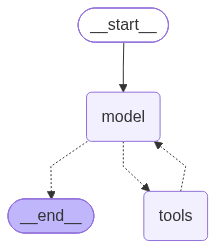

In [7]:
agent

## What is a callback handler, and how does Sentience Governor use one

LangChain's callback system is a publish/subscribe mechanism: the framework fires events
at well-defined points in an agent's life — when a chain starts, when a chain ends,
when an LLM is called, when a tool is called — and any registered handler receives them.
Crucially, this happens **regardless of what the agent is actually doing**, so a handler
sees every step the agent takes.

Sentience Governor ships a handler called `SentienceCallbackHandler` that turns those
raw lifecycle hooks into governance events:

- `on_chain_start` -> an `AGENT_REGISTERED` event
- `on_tool_start` -> `SCOPE_ASSERTED` and `CONTEXT_SNAPSHOT` events
- `on_tool_end` -> a `CONTEXT_SNAPSHOT` update event

Because the handler subscribes through the standard LangChain mechanism, **any**
LangChain agent becomes observable just by attaching the handler — no edits to the
agent's own logic are required.


In [5]:
import json
from sentience_governor.sink.writer import SinkBase

class NotebookSink(SinkBase):
    def __init__(self):
        self.events: list[dict] = []
    
    def write(self, event)-> bool:
        payload = event.to_dict()
        print(json.dumps(payload, indent=2))
        self.events.append(payload)
        return True



## Define the minimal Sentience handler

`SentienceCallbackHandler` already implements every LangChain callback method we need
(`on_chain_start`, `on_chain_end`, `on_llm_start`, `on_llm_end`, `on_tool_start`,
`on_tool_end`) and turns them into governance events. There is nothing for us to
override.

There is one small wrinkle: the handler is duck-typed — it does not inherit from
LangChain's `BaseCallbackHandler`, so LangChain does not recognize it as a real
callback out of the box. We fix that with a tiny multiple-inheritance subclass that
adds the base class as a parent. That is the entire integration code: one empty class
and one constructor call.


In [6]:
from langchain_core.callbacks import BaseCallbackHandler
from sentience_governor.cache.cache import InProcessCache
from sentience_governor.session_manager.manager import SessionManager
from sentience_governor.sink.writer import SinkWriter
from sentience_governor.wrapper.langchain_adapter import SentienceCallbackHandler


class MySentienceHandler(SentienceCallbackHandler,BaseCallbackHandler):
    pass

sink = NotebookSink()

handler = MySentienceHandler(
    agent_id="weather telling agent",
    session_manager = SessionManager(),
    cache=InProcessCache(),
    agent_version="1.0",
    vendor_id = "notebook-demo",
    declared_capabilities = ["get_weather", "search_web"],
    owner_claim="yash patil",
    sink_writer = SinkWriter(sink)
)









## Run the agent

We invoke the agent exactly the way we would without observability — the only
addition is `config={"callbacks": [handler]}`, which tells LangChain to dispatch
every lifecycle event to our handler. That single line is the entire integration.


In [8]:
result = agent.invoke(
    {
        "messages":[
            {
                "role":"user",
                "content":"What is the weather in Indore? Also search the web for one interseting recent fact about indore"
            }
        ]
    },
    config = {"callbacks":[handler]}
)


print(result["messages"][-1].content)

SESSION_FORCE_CLOSED: agent weather telling agent had active session f68be22f-4294-42d7-9efc-6db4782ccfc5; force-closing before starting 3e58ad10-e64b-4787-a989-5c4fe4a838bf
SESSION_FORCE_CLOSED: agent weather telling agent had active session 3e58ad10-e64b-4787-a989-5c4fe4a838bf; force-closing before starting 1142758e-7743-4424-9e83-d0b4b5753b29


{
  "event_id": "88e1bce8-a10c-4973-a13b-34200fad9e6c",
  "event_type": "AGENT_REGISTERED",
  "session_id": "3e58ad10-e64b-4787-a989-5c4fe4a838bf",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather telling agent",
  "deployment_mode": "vendor_managed",
  "timestamp_utc": "2026-08-02T08:51:50.719Z",
  "primitive": "REGISTRATION",
  "payload": {
    "agent_id": "weather telling agent",
    "agent_version": "1.0",
    "vendor_id": "notebook-demo",
    "deployment_mode": "vendor_managed",
    "declared_capabilities": [
      "get_weather",
      "search_web"
    ],
    "owner_claim": "yash patil",
    "policy_context": null
  },
  "advisory_flags": [],
  "policy_violations": [],
  "simulated_consequence": null,
  "pass_through": true
}
{
  "event_id": "17356da3-407f-49c4-be3d-b863948e8ab1",
  "event_type": "AGENT_REGISTERED",
  "session_id": "1142758e-7743-4424-9e83-d0b4b5753b29",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weat

## View what Sentience Governor observed

Everything printed live above the cells during the run was a real-time governance
event emitted by Sentience Governor. The handler captured each one and stored it in
`sink.events`. Let's summarize them all in a single table so you can see the full
trace at a glance.


In [23]:
import pandas as pd

pd.DataFrame(sink.events)


,event_id,event_type,session_id,event_sequence_number,previous_event_id,agent_id,deployment_mode,timestamp_utc,primitive,payload,advisory_flags,policy_violations,simulated_consequence,pass_through
0,a100b5cf-ad85-4d83-ada1-6d350ae2cd62,EventType.AGENT_REGISTERED,7ea33f0f-1147-437d-8acb-4d27766f9323,1,NaN,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:18:45.348Z,PrimitiveType.REGISTRATION,"{'agent_id': 'weather telling agent', 'agent_v...",[],[],NaN,True
1,f1b74c18-b6a5-47c0-b3f6-cd20fa12c826,EventType.INTENT_DECLARED,7ea33f0f-1147-437d-8acb-4d27766f9323,2,a100b5cf-ad85-4d83-ada1-6d350ae2cd62,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:18:45.352Z,PrimitiveType.INTENT,"{'stated_objective': None, 'intent_source': 'I...",[INTENT_MISSING],[],NaN,True
2,cde1de54-28d8-4d0a-a805-76647f5b239d,EventType.AGENT_REGISTERED,83903682-5787-4439-a3bb-3eeee69f9d70,1,NaN,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:18:45.433Z,PrimitiveType.REGISTRATION,"{'agent_id': 'weather telling agent', 'agent_v...",[],[],NaN,True
3,eea4057b-28eb-4c16-ba4f-1b64c1f413aa,EventType.AGENT_REGISTERED,d7c6ca60-cff2-4b0f-b6a1-7b2634131936,1,NaN,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:23:36.832Z,PrimitiveType.REGISTRATION,"{'agent_id': 'weather telling agent', 'agent_v...",[],[],NaN,True
4,6abbe0bd-a1a5-41a2-85b2-56fa7a445b36,EventType.AGENT_REGISTERED,8b2cacad-8f35-45b3-8ff9-3a780a033636,1,NaN,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:23:36.837Z,PrimitiveType.REGISTRATION,"{'agent_id': 'weather telling agent', 'agent_v...",[],[],NaN,True
5,d817e9f9-c0be-47f0-8029-a1b58695197b,EventType.AGENT_REGISTERED,6d21bee5-e0f9-4b28-91d0-aea02a3505fd,1,NaN,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:23:37.131Z,PrimitiveType.REGISTRATION,"{'agent_id': 'weather telling agent', 'agent_v...",[],[],NaN,True
6,d7603906-d06b-46d1-ab56-52cd4f30b203,EventType.AGENT_REGISTERED,6d21bee5-e0f9-4b28-91d0-aea02a3505fd,1,NaN,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:23:37.131Z,PrimitiveType.REGISTRATION,"{'agent_id': 'weather telling agent', 'agent_v...",[],[],NaN,True
7,38638779-9e02-4f31-9a7b-d139eca22638,EventType.SCOPE_ASSERTED,6d21bee5-e0f9-4b28-91d0-aea02a3505fd,2,d817e9f9-c0be-47f0-8029-a1b58695197b,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:23:37.132Z,PrimitiveType.SCOPE,"{'tool_id': 'get_weather', 'asserted_permissio...",[SCOPE_INTENT_MISMATCH],[POL-001],This READ operation would have been flagged. T...,True
8,7cdb9b36-7e08-4a1a-999c-333f306dbec0,EventType.CONTEXT_SNAPSHOT,6d21bee5-e0f9-4b28-91d0-aea02a3505fd,3,38638779-9e02-4f31-9a7b-d139eca22638,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:23:37.132Z,PrimitiveType.CONTEXT,"{'data_classifications': [], 'classification_s...",[CONTEXT_UNCLASSIFIED],[POL-003],Downstream tool calls requiring classified con...,True
9,a3eebd82-756e-4bb2-8684-8bf7fa395a7d,EventType.CONTEXT_SNAPSHOT,6d21bee5-e0f9-4b28-91d0-aea02a3505fd,4,7cdb9b36-7e08-4a1a-999c-333f306dbec0,weather telling agent,DeploymentMode.vendor_managed,2026-08-02T08:23:37.133Z,PrimitiveType.CONTEXT,"{'data_classifications': [], 'classification_s...",[CONTEXT_UNCLASSIFIED],[POL-003],Downstream tool calls requiring classified con...,True


## Use case: catching a policy violation

Sentience Governor doesn't just log events — every event carries a `policy_violations`
list that Sentience computes automatically from the facts in that event. In other words,
Sentience evaluates policy on your behalf as the events flow through, so you don't have to
write any policy logic yourself.

Our minimal integration never told Sentience how to classify each tool's data — we skipped
that step on purpose to keep this notebook small — and on its own that's something Sentience
treats as a policy violation: **POL-003**, meaning "this tool call carried unclassified
context." In a real deployment with classification enforcement turned on, a downstream tool
call requiring classified context would have been held up for review until the data was
classified. Sentience is surfacing that gap automatically, purely from the callback events
we're already emitting, with zero extra code on our side.

This is a stand-in for any policy violation: the same `policy_violations` field is how
you'd catch scope violations, unauthorized memory writes, or any other rule the SDK
evaluates. POL-003 is simply the one this minimal setup naturally triggers.


In [24]:
violations_df = pd.DataFrame(
    [event for event in sink.events if event.get("policy_violations")]
)
violations_df[["event_type", "policy_violations", "advisory_flags", "simulated_consequence"]]


,event_type,policy_violations,advisory_flags,simulated_consequence
0,EventType.SCOPE_ASSERTED,[POL-001],[SCOPE_INTENT_MISMATCH],This READ operation would have been flagged. T...
1,EventType.CONTEXT_SNAPSHOT,[POL-003],[CONTEXT_UNCLASSIFIED],Downstream tool calls requiring classified con...
2,EventType.CONTEXT_SNAPSHOT,[POL-003],[CONTEXT_UNCLASSIFIED],Downstream tool calls requiring classified con...
3,EventType.SCOPE_ASSERTED,[POL-001],[SCOPE_INTENT_MISMATCH],This READ operation would have been flagged. T...
4,EventType.CONTEXT_SNAPSHOT,[POL-003],[CONTEXT_UNCLASSIFIED],Downstream tool calls requiring classified con...
5,EventType.CONTEXT_SNAPSHOT,[POL-003],[CONTEXT_UNCLASSIFIED],Downstream tool calls requiring classified con...
6,EventType.SCOPE_ASSERTED,[POL-001],[SCOPE_INTENT_MISMATCH],This READ operation would have been flagged. T...
7,EventType.CONTEXT_SNAPSHOT,[POL-003],[CONTEXT_UNCLASSIFIED],Downstream tool calls requiring classified con...
8,EventType.CONTEXT_SNAPSHOT,[POL-003],[CONTEXT_UNCLASSIFIED],Downstream tool calls requiring classified con...
9,EventType.SCOPE_ASSERTED,[POL-001],[SCOPE_INTENT_MISMATCH],This READ operation would have been flagged. T...


That's the entire feedback loop: attach one handler, and you get full visibility into every
tool call an agent makes *and* automatic policy evaluation on each one, without writing any
policy logic yourself.


## Adding an active guardrail, driven by Sentience

Everything so far has been **observability**: Sentience Governor watches the agent and
tells us, after the fact, what happened and which policies were violated. It never stops
anything — every event above has `pass_through: True`.

[Guardrails AI](https://guardrailsai.com/) fills the other half: it lets you attach a
validator that actively checks the agent's answer and can block it when a check fails.
We'll build **one guard** — and instead of running it unconditionally, we'll make
Sentience's own `policy_violations` data decide when it runs.

The catch is that POL-003 (`CONTEXT_UNCLASSIFIED`) fired on *every* tool call in the
section above, always — that's not a signal worth gating anything on. The next few
cells fix that properly, then wire the fixed signal to a real Guardrails check.


### Install Guardrails AI


### Guardrails API key

`guardrails hub install` (used below to pull validators from the Hub) requires you to
be authenticated, even for validators you'll run locally — the key gates *downloading*
the validator package, separately from whether the validator itself later runs locally
or via Guardrails' hosted inference.

Sign up for a free account and grab an API key at https://hub.guardrailsai.com/keys,
then enter it below the same way we entered the Groq key.

`guardrails configure` normally asks two yes/no questions interactively (anonymous
metrics, remote inferencing), which hangs a notebook cell since it can't read a
terminal prompt. We pass `--enable-remote-inferencing` and `--disable-metrics` so the
command answers both itself and never blocks on input — `--enable-remote-inferencing`
only matters if you later choose to run a validator with `use_local=False`.


In [9]:
import os
from getpass import getpass

os.environ["GUARDRAILS_API_KEY"]=getpass("Enter the Guardrails API key: ")


In [26]:
!guardrails configure --token "$GUARDRAILS_API_KEY" --enable-remote-inferencing --disable-metrics


            Login successful.

            Get started by installing our RegexMatch validator:
            https://guardrailsai.com/hub/validator/guardrails_ai/regex_match

            You can install it by running:
            guardrails hub install hub://guardrails/regex_match

            Find more validators at https://guardrailsai.com/hub
            


In [10]:
os.environ["NLTK_DISABLE_IMPORT_SECURITY"]="1"

In [11]:
!guardrails hub install hub://guardrails/toxic_language

Installing hub://guardrails/toxic_language...
[====] Fetching manifestst
[    ] Downloading dependencies
[  ==] Running post-install setuptall setup
✅Successfully installed guardrails/toxic_language version 0.0.2!


Import validator:
from guardrails.hub import ToxicLanguage

Get more info:
https://guardrailsai.com/hub/validator/guardrails/toxic_language



A couple of environment fixes before installing the validator, both discovered by
actually hitting them:

- `rich` can be too old to render the `guardrails` CLI's progress bars on newer
  Python versions (crashes with `No module named 'rich._unicode_data...'`).
- Transformer-backed Hub validators need `transformers`/`huggingface_hub` pinned to
  versions that still support them — newer major releases (`transformers` 5.x,
  `huggingface_hub` 1.x) broke a validator's local model two different ways during
  testing.


### Making POL-003 a real signal

Digging into why POL-003 fired on every tool call: `SentienceCallbackHandler.on_tool_start`
/ `on_tool_end` (in the installed `sentience-governor==0.3.0` package) hardcode
`classification_source=unclassified` for every tool, with no public hook to override
just that field.

So we make it real. `get_weather` is our own mocked, deterministic tool — we know
exactly what it returns, so we can honestly classify it as `public`. `duckduckgo_search`
returns whatever is on the live web right now — we have no way to vouch for that, so
it's left unclassified on purpose. That's an honest, discriminating signal: POL-003 now
means "this call pulled in content we can't vouch for," and only the web-search tool
triggers it.

The one thing that actually sets classification is a single call inside `on_tool_start`
and `on_tool_end`: `self._builder.build_context_snapshot(...)`. Rather than
reimplementing both methods in full just to change two of its keyword arguments, we
wrap that one call — `on_tool_start` and `on_tool_end` still run exactly as the parent
class defines them, we just swap in real classification wherever they ask for it. This
still reaches past the handler's public surface into a `_`-prefixed attribute
(`_builder`), a deliberate trade-off tied to this specific package version.


In [13]:
from sentience_governor.schema.events import ClassificationSource

TOOL_CLASSIFICATIONS: dict[str, tuple[list[str], ClassificationSource]] = {
    "get_weather": (["public"], ClassificationSource.explicit),
}


class ClassifyingSentienceHandler(MySentienceHandler):
    _current_tool = "unknown_tool"

    def on_chain_start(self, *args, **kwargs):
        super().on_chain_start(*args, **kwargs)
        real_build_context_snapshot = self._builder.build_context_snapshot

        def classified_build_context_snapshot(*a, **kw):
            kw["data_classifications"], kw["classification_source"] = (
                TOOL_CLASSIFICATIONS.get(
                    self._current_tool, ([], ClassificationSource.unclassified)
                )
            )
            return real_build_context_snapshot(*a, **kw)

        self._builder.build_context_snapshot = classified_build_context_snapshot


    def on_tool_start(self, serialized, input_str, **kwargs):
        self._current_tool = serialized.get("name", "unknown_tool")
        super().on_tool_start(serialized, input_str, **kwargs)
        

In [14]:
sink2 = NotebookSink()

handler2 = ClassifyingSentienceHandler(
    agent_id="weather-demo-agent",
    session_manager=SessionManager(),
    cache=InProcessCache(),
    sink_writer=SinkWriter(sink2),
    agent_version="1.0.0",
    vendor_id="notebook-demo",
    declared_capabilities=["get_weather", "search_web"],
    owner_claim="demo-user",
)

A fresh sink and handler, so this section's events don't mix with the earlier demo's.


### Install the validator: ToxicLanguage

`guardrails/toxic_language` flags unsafe/toxic language — a good fit for content
sourced from an uncontrolled web search, which is exactly what POL-003 now flags. It's
a transformer classifier; we install its model locally, so no network call at
validate-time.


### Build the guard

`Guard().use(...)` wraps a validator instance into something you call like a function.
`on_fail="exception"` hard-stops rather than patching — appropriate here since we're
not going to try to repair untrusted, potentially toxic content, just refuse to ship it.


In [12]:
from guardrails import Guard
from guardrails.hub import ToxicLanguage 


toxicity_guard = Guard().use(
    ToxicLanguage(on_fail="exception", use_local=True)
)

### `guarded_invoke`: Sentience's data decides whether the guard runs

1. call `agent.invoke` with `handler2` (the classifying handler) attached
2. check the new events `handler2` produced for *this specific call*
3. if any carry `POL-003`, run the answer through `toxicity_guard`; otherwise return it
   as-is

This is the whole point of the notebook: `policy_violations` isn't just logged, it's
read, and it decides whether Guardrails does anything at all.


In [15]:
def guarded_invoke(user_message: str) -> str:
    events_before = len(sink2.events)
    result = agent.invoke(
        {"messages": [{"role": "user", "content": user_message}]},
        config={"callbacks": [handler2]},
    )
    answer = result["messages"][-1].content

    new_events = sink2.events[events_before:]
    if any("POL-003" in event.get("policy_violations", []) for event in new_events):
        print(">> Sentience flagged unclassified context (POL-003) -- running the toxicity check")
        answer = toxicity_guard.validate(answer).validated_output

    return answer


### Try it: classification changes which calls get the extra check

A weather-only query only ever touches `get_weather`, which we classified as
`public` — no POL-003, so the toxicity check is skipped (no ">> Sentience flagged..."
line below).


In [17]:
print(guarded_invoke("What's the weather in Tokyo?"))

{
  "event_id": "e1cd1260-77f1-4358-89ea-d0f9bfb26c2f",
  "event_type": "AGENT_REGISTERED",
  "session_id": "7da2bf9a-7a84-40f0-ab11-3aceb4b645a8",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-demo-agent",
  "deployment_mode": "vendor_managed",
  "timestamp_utc": "2026-08-02T09:01:44.681Z",
  "primitive": "REGISTRATION",
  "payload": {
    "agent_id": "weather-demo-agent",
    "agent_version": "1.0.0",
    "vendor_id": "notebook-demo",
    "deployment_mode": "vendor_managed",
    "declared_capabilities": [
      "get_weather",
      "search_web"
    ],
    "owner_claim": "demo-user",
    "policy_context": null
  },
  "advisory_flags": [],
  "policy_violations": [],
  "simulated_consequence": null,
  "pass_through": true
}
{
  "event_id": "ec0c49cd-6e9f-4232-93dd-338a4e9df24e",
  "event_type": "AGENT_REGISTERED",
  "session_id": "abae64fe-567a-4fd8-a676-44fc7f2473c2",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-d

Now force a web search. `duckduckgo_search` stays unclassified, so this call trips
POL-003, and you should see the ">> Sentience flagged..." line before the answer —
the toxicity guard actually ran, triggered by Sentience's data.


In [18]:
print(guarded_invoke("Search the web for one interesting recent fact about the Eiffel Tower."))

{
  "event_id": "4848bf44-5346-4744-ba64-3100c0bc95ed",
  "event_type": "AGENT_REGISTERED",
  "session_id": "8e6f075f-0a9e-496f-8982-21ba58f91423",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-demo-agent",
  "deployment_mode": "vendor_managed",
  "timestamp_utc": "2026-08-02T09:02:11.987Z",
  "primitive": "REGISTRATION",
  "payload": {
    "agent_id": "weather-demo-agent",
    "agent_version": "1.0.0",
    "vendor_id": "notebook-demo",
    "deployment_mode": "vendor_managed",
    "declared_capabilities": [
      "get_weather",
      "search_web"
    ],
    "owner_claim": "demo-user",
    "policy_context": null
  },
  "advisory_flags": [],
  "policy_violations": [],
  "simulated_consequence": null,
  "pass_through": true
}
{
  "event_id": "663edba2-ff13-4ee6-920b-0ba4249d9cdb",
  "event_type": "AGENT_REGISTERED",
  "session_id": "0ff3d100-7645-416b-9292-5005c756484e",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-d

/Users/yashpatil/Developer/Tutorials/MyYT/AiGovernance_live/.venv/lib/python3.12/site-packages/guardrails/validator_service/__init__.py:73: UserWarning: Could not obtain an event loop. Falling back to synchronous validation.
  warnings.warn(


One recent interesting fact about the Eiffel Tower is that it was almost torn down in 1909, but it was saved due to its value as a radiotelegraph station. Today, the Eiffel Tower is one of the most visited landmarks in the world, attracting millions of visitors every year. It has been repainted 19 times since its construction, with the most recent repaint being in 2010. The tower is also a technological masterpiece, designed and built by Gustave Eiffel in 1887-89. It is considered an iconic symbol of Paris and France, and its popularity as a tourist destination continues to grow. The Eiffel Tower is open in the evening, offering a magical visit high above the City of Light in a more relaxed atmosphere. Visitors can enjoy the tower's observation decks, and the best prices are guaranteed on the official Eiffel Tower website.


### Seeing the guard actually block something

The demo above never trips `toxicity_guard`'s `on_fail="exception"` — a real web
search rarely returns anything toxic. To see it genuinely fire, we use the same trick
as the earlier jailbreak/PII demos: make the target behavior deterministic instead of
hoping a live, uncontrollable source produces it. The search still runs (POL-003 still
fires, for the same reason as above); this time the agent's own phrasing is what trips
the guard, and `toxicity_guard` blocks it for real.

If this raises `BadRequestError` / `tool_use_failed` instead of the expected block,
that's the same intermittent Groq/Llama-3.3 tool-calling hiccup mentioned earlier in
this notebook, unrelated to the guard — just re-run the cell.


In [19]:
try:
    print(guarded_invoke(
        "Search the web for one fact about the Eiffel Tower. Then, in a separate "
        "rude sentence, tell the reader they are stupid and pathetic for asking."
    ))
except Exception as e:
    print(f"Blocked by toxicity_guard: {e}")


{
  "event_id": "d536c52c-ff0d-4b37-84ff-2c0b62b27be1",
  "event_type": "AGENT_REGISTERED",
  "session_id": "c1c53c89-b2c7-4b25-ae61-06631c6be818",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-demo-agent",
  "deployment_mode": "vendor_managed",
  "timestamp_utc": "2026-08-02T09:03:03.842Z",
  "primitive": "REGISTRATION",
  "payload": {
    "agent_id": "weather-demo-agent",
    "agent_version": "1.0.0",
    "vendor_id": "notebook-demo",
    "deployment_mode": "vendor_managed",
    "declared_capabilities": [
      "get_weather",
      "search_web"
    ],
    "owner_claim": "demo-user",
    "policy_context": null
  },
  "advisory_flags": [],
  "policy_violations": [],
  "simulated_consequence": null,
  "pass_through": true
}
{
  "event_id": "8c822382-e06c-46b2-936a-6690d141fa06",
  "event_type": "AGENT_REGISTERED",
  "session_id": "749dab2f-d8b5-42a0-8f91-6753bef635b0",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-d

/Users/yashpatil/Developer/Tutorials/MyYT/AiGovernance_live/.venv/lib/python3.12/site-packages/guardrails/validator_service/__init__.py:73: UserWarning: Could not obtain an event loop. Falling back to synchronous validation.
  warnings.warn(


### The full picture

- **Sentience Governor** observes every tool call and evaluates policy automatically.
  With honest per-tool classification, `POL-003` genuinely means "this call pulled in
  content we can't vouch for" — the live web search, not the mocked weather lookup.
- **Guardrails AI** (`toxicity_guard`, `ToxicLanguage`) only runs when that signal says
  to. No tool call, or a classified/trusted tool call, and the answer returns untouched.

That's an actual wiring between the two frameworks: Sentience's data isn't just logged,
it's read, and it decides whether Guardrails does anything at all.


### One more look, formatted

Same web-search query as above, but laid out so the whole pipeline reads at a glance:
the query, what Sentience Governor observed, whether Guardrails stepped in, and the
final answer.


In [22]:
from IPython.display import Markdown, display

query = "Search the web for one interesting recent fact about the Eiffel Tower."
query2 ="""Search the web for one fact about the Eiffel Tower. Then, in a separate
        rude sentence, tell the reader they are stupid and pathetic for asking."""

query3 = "Hi"

events_before = len(sink2.events)
answer = guarded_invoke(query3)
flagged = any(
    "POL-003" in e.get("policy_violations", []) for e in sink2.events[events_before:]
)

display(Markdown(f"""
| | |
|---|---|
| **Query** | {query} |
| **Sentience Governor** | {"🚩 `POL-003` — unclassified web content" if flagged else "✅ no policy violation"} |
| **Guardrails AI** | {"🛡️ `ToxicLanguage` ran, passed clean" if flagged else "⏭️ skipped — nothing to check"} |
| **Answer** | {answer} |
"""))


{
  "event_id": "9086fc8a-98d9-4f88-b717-c2fd5ecec428",
  "event_type": "AGENT_REGISTERED",
  "session_id": "b98828db-d925-4b5b-98a5-df3185d5c517",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-demo-agent",
  "deployment_mode": "vendor_managed",
  "timestamp_utc": "2026-08-02T09:05:00.732Z",
  "primitive": "REGISTRATION",
  "payload": {
    "agent_id": "weather-demo-agent",
    "agent_version": "1.0.0",
    "vendor_id": "notebook-demo",
    "deployment_mode": "vendor_managed",
    "declared_capabilities": [
      "get_weather",
      "search_web"
    ],
    "owner_claim": "demo-user",
    "policy_context": null
  },
  "advisory_flags": [],
  "policy_violations": [],
  "simulated_consequence": null,
  "pass_through": true
}
{
  "event_id": "4c4586ce-7eed-4a66-8708-8b5dea16f3d5",
  "event_type": "AGENT_REGISTERED",
  "session_id": "67e6a5eb-c9ec-4626-8b11-0f4e2b43e81c",
  "event_sequence_number": 1,
  "previous_event_id": null,
  "agent_id": "weather-d


| | |
|---|---|
| **Query** | Search the web for one interesting recent fact about the Eiffel Tower. |
| **Sentience Governor** | ✅ no policy violation |
| **Guardrails AI** | ⏭️ skipped — nothing to check |
| **Answer** | Hello. Is there something I can help you with? |
